# Tarea Corta 2 — Árboles de Decisión

**Curso:** Inteligencia Artificial
**Integrantes:** María Felix Mendez Abarca, Cristhian Rivas y Jozafath Perez
**Descripción:** Implementación desde cero de un árbol de decisión, validación cruzada y comparación de 10 combinaciones de hiperparámetros sobre el dataset adult-census.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.arbol import ArbolDecision
from src.datos import cargar_datos, train_test_split_manual
from src.evaluacion import accuracy, precision, recall, f1, validacion_cruzada
from experimentos import COMBINACIONES, correr_experimentos, escoger_mejor

pd.set_option("display.precision", 3)
K = 5  # folds de la validación cruzada

## Datos

Cada fila es una persona del censo de EE. UU. y la clase dice si gana más de 50K al año (`1`) o no (`0`).

`cargar_datos` limpia el CSV: las etiquetas y todo el texto venían con un espacio al inicio (`' >50K'`, `' Private'`),
la clase se pasa a 0/1 y los `?` (dato faltante en `workclass`, `occupation` y `native-country`) quedan como una categoría más.

Se separa un 20 % como **test** con la semilla 42. Ese conjunto no se toca hasta la última sección:
todos los experimentos y la elección del modelo se hacen solo con el 80 % de entrenamiento.

In [2]:
X, y = cargar_datos()
X_train, X_test, y_train, y_test = train_test_split_manual(X, y)

print(f"{len(y)} personas, {X.shape[1]} variables")
print(f"Train: {len(y_train)}   Test: {len(y_test)}")
print(f"Ganan >50K -> train: {y_train.mean():.1%}   test: {y_test.mean():.1%}")
X.head()

48842 personas, 13 variables
Train: 39074   Test: 9768
Ganan >50K -> train: 23.9%   test: 24.0%


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States
4,18,?,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States


Las clases están **desbalanceadas**: solo ~24 % gana más de 50K. Un modelo que siempre diga "no gana más de 50K"
ya tendría ~76 % de accuracy sin aprender nada (su F1 sería 0). Por eso el accuracy solo no basta para comparar modelos
y se usa el **F1** de la clase positiva, que combina precision y recall.

### ¿Cómo codificar las variables categóricas?

Un árbol compara números (`x <= umbral`), pero `workclass`, `education`, etc. son texto. Hay tres opciones:

1. **Ordinal:** darle un número a cada categoría (`Bachelors=0`, `Doctorate=1`, …). Es rápido, pero inventa un orden que no existe
   y el árbol solo puede cortar "las categorías con número menor que tal".
2. **One-hot:** una columna 0/1 por categoría (107 columnas). No inventa orden, pero cada corte separa una sola categoría del resto.
3. **Texto, y que el árbol agrupe:** en cada nodo el árbol ordena las categorías por su proporción de `>50K` y busca el mejor
   corte en ese orden. Así encuentra la mejor división en dos grupos (resultado de Breiman, CART).

Se comparan con validación cruzada usando el modelo escogido más abajo:

In [3]:
params = {"max_depth": 10, "min_split_samples": 300, "criterio": "gini"}
texto = [c for c in X_train.columns if X_train[c].dtype.kind not in "iuf"]
ordinal = X_train.copy()
for c in texto:
    ordinal[c] = ordinal[c].astype("category").cat.codes
one_hot = pd.get_dummies(X_train, columns=texto, dtype=float)

opciones = {"ordinal": ordinal.to_numpy(float), "one-hot": one_hot.to_numpy(), "texto (el árbol agrupa)": X_train}
pd.DataFrame({nombre: validacion_cruzada(ArbolDecision, params, Xc, y_train, k=K) | {"columnas": Xc.shape[1]}
              for nombre, Xc in opciones.items()}).T[["columnas", "accuracy_media", "f1_media", "f1_desv"]]

,columnas,accuracy_media,f1_media,f1_desv
ordinal,13.0,0.855,0.644,0.010
one-hot,107.0,0.859,0.660,0.009
texto (el árbol agrupa),13.0,0.857,0.667,0.015


Dejar el texto y que el árbol agrupe las categorías da el mejor F1, con solo 13 columnas. Por eso `cargar_datos` no convierte
las categóricas a números: esa codificación la hace `ArbolDecision`, y la mejor partición se recalcula en cada nodo.

## Experimentos

Se evalúan 10 combinaciones con validación cruzada de 5 folds sobre el train. Se cambia **un hiperparámetro a la vez**
para poder atribuirle el efecto:

| Modelos | Qué se varía | Fijo |
| --- | --- | --- |
| M1–M6 | `max_depth`: 2, 4, 6, 10, 15 y sin límite | `min_split_samples=2`, gini |
| M7–M8 | `min_split_samples`: 50 y 300 (comparar con M4, que tiene 2) | `max_depth=10`, gini |
| M9–M10 | `criterio="entropia"` (comparar con M3 y M7) | los mismos parámetros que M3 y M7 |

Además de las métricas de validación, cada combinación se entrena una vez con todo el train para medir su
**accuracy en train** (si es mucho mayor que la de validación, hay sobreajuste) y su tamaño (`hojas`).

In [4]:
tabla = correr_experimentos(X_train, y_train, k=K)

M1   {'max_depth': 2, 'min_split_samples': 2, 'criterio': 'gini'}  F1=0.564 ± 0.011


M2   {'max_depth': 4, 'min_split_samples': 2, 'criterio': 'gini'}  F1=0.605 ± 0.011


M3   {'max_depth': 6, 'min_split_samples': 2, 'criterio': 'gini'}  F1=0.631 ± 0.011


M4   {'max_depth': 10, 'min_split_samples': 2, 'criterio': 'gini'}  F1=0.671 ± 0.013


M5   {'max_depth': 15, 'min_split_samples': 2, 'criterio': 'gini'}  F1=0.663 ± 0.007


M6   {'max_depth': None, 'min_split_samples': 2, 'criterio': 'gini'}  F1=0.611 ± 0.006


M7   {'max_depth': 10, 'min_split_samples': 50, 'criterio': 'gini'}  F1=0.673 ± 0.013


M8   {'max_depth': 10, 'min_split_samples': 300, 'criterio': 'gini'}  F1=0.667 ± 0.015


M9   {'max_depth': 6, 'min_split_samples': 2, 'criterio': 'entropia'}  F1=0.627 ± 0.007


M10  {'max_depth': 10, 'min_split_samples': 50, 'criterio': 'entropia'}  F1=0.671 ± 0.014


In [5]:
columnas = ["modelo", "max_depth", "min_split_samples", "criterio",
            "accuracy_media", "precision_media", "recall_media", "f1_media", "f1_desv",
            "accuracy_train", "profundidad_real", "hojas", "tiempo_s"]
tabla[columnas]

,modelo,max_depth,min_split_samples,criterio,accuracy_media,precision_media,recall_media,f1_media,f1_desv,accuracy_train,profundidad_real,hojas,tiempo_s
0,M1,2,2,gini,0.829,0.723,0.463,0.564,0.011,0.830,2,4,1.3
1,M2,4,2,gini,0.847,0.790,0.491,0.605,0.011,0.848,4,16,1.9
2,M3,6,2,gini,0.854,0.800,0.522,0.631,0.011,0.856,6,52,2.7
3,M4,10,2,gini,0.856,0.741,0.614,0.671,0.013,0.875,10,297,5.9
4,M5,15,2,gini,0.846,0.695,0.634,0.663,0.007,0.899,15,1260,15.8
5,M6,<NA>,2,gini,0.812,0.606,0.616,0.611,0.006,0.974,43,6538,39.3
6,M7,10,50,gini,0.858,0.748,0.612,0.673,0.013,0.871,10,193,2.8
7,M8,10,300,gini,0.857,0.749,0.601,0.667,0.015,0.866,10,123,2.6
8,M9,6,2,entropia,0.854,0.806,0.513,0.627,0.007,0.856,6,48,1.6
9,M10,10,50,entropia,0.857,0.746,0.611,0.671,0.014,0.866,10,186,2.5


Las columnas `_media` son el promedio de los 5 folds de validación y `f1_desv` su desviación estándar.
`max_depth = <NA>` significa sin límite.

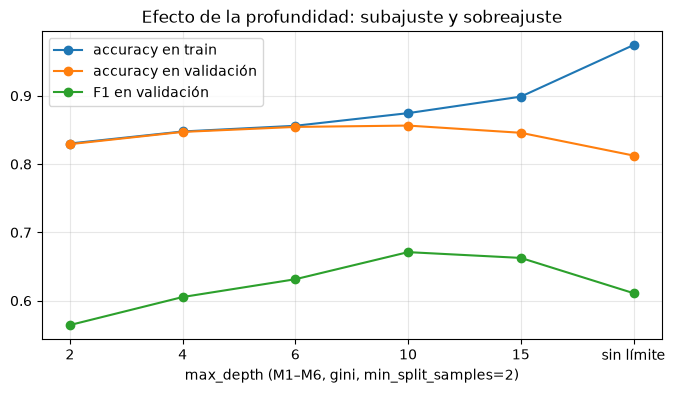

In [6]:
prof = tabla.iloc[:6]
etiquetas = [str(d) if pd.notna(d) else "sin límite" for d in prof["max_depth"]]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(etiquetas, prof["accuracy_train"], "o-", label="accuracy en train")
ax.plot(etiquetas, prof["accuracy_media"], "o-", label="accuracy en validación")
ax.plot(etiquetas, prof["f1_media"], "o-", label="F1 en validación")
ax.set_xlabel("max_depth (M1–M6, gini, min_split_samples=2)")
ax.set_title("Efecto de la profundidad: subajuste y sobreajuste")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Profundidad.** Con árboles poco profundos (M1, M2) el modelo es demasiado simple: train y validación dan casi lo mismo
pero ambos bajos (**subajuste**). Al crecer hasta profundidad 10 (M4) el F1 de validación sube de 0.56 a 0.67.
De ahí en adelante el accuracy en train sigue subiendo, pero el de validación baja: el árbol sin límite (M6) llega a
profundidad 43, tiene más de 6500 hojas y acierta 97 % en train pero solo 81 % en validación. Está memorizando el
entrenamiento (**sobreajuste**).

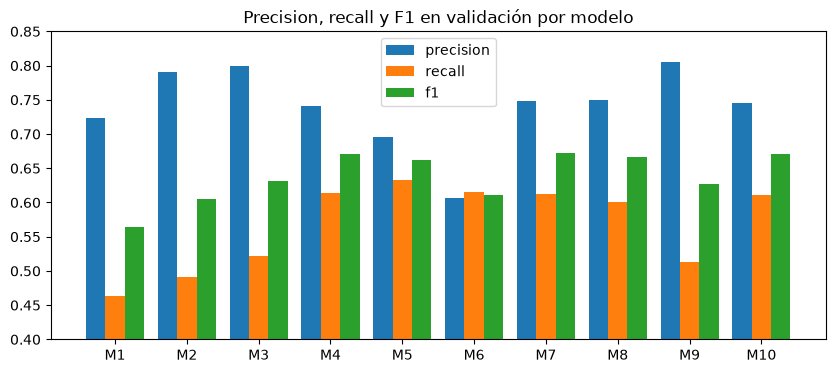

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(tabla))
for i, metrica in enumerate(["precision", "recall", "f1"]):
    ax.bar(x + (i - 1) * 0.27, tabla[f"{metrica}_media"], width=0.27, label=metrica)
ax.set_xticks(x, tabla["modelo"])
ax.set_ylim(0.4, 0.85)
ax.set_title("Precision, recall y F1 en validación por modelo")
ax.legend()
plt.show()

**Precision vs. recall.** Los árboles chicos son conservadores: cuando dicen ">50K" suelen acertar (precision ~0.8),
pero se les escapa la mitad de los que sí ganan más (recall ~0.5). Los árboles más profundos encuentran más casos positivos
(recall ~0.61) a cambio de algo de precision, y el F1 mejora.

**`min_split_samples`.** Con profundidad 10, subirlo de 2 (M4) a 50 (M7) o 300 (M8) casi no cambia el F1 (0.671, 0.673, 0.667)
pero reduce el árbol de 297 a 193 y 123 hojas y lo entrena el doble de rápido. Impide cortes en nodos con pocas personas,
que son justamente los que sirven para memorizar casos raros.

**Criterio.** Gini y entropía dan resultados prácticamente iguales (M3 vs M9: 0.631 vs 0.627; M7 vs M10: 0.673 vs 0.671).
Las diferencias son mucho menores que la desviación entre folds, así que el criterio no es una decisión importante aquí.

## Análisis del mejor modelo

**Métrica para escoger:** F1 medio en validación, por el desbalance de clases explicado arriba.

**Regla de un error estándar.** Varios modelos quedan muy cerca del mejor F1, y esas diferencias pueden ser solo ruido de cómo
cayeron los folds. El error estándar de la media es `desv / √k`. Entre todos los modelos cuyo F1 está a menos de un error
estándar del mejor, se escoge el **más simple** (menos hojas): rinde igual dentro del margen de error, generaliza más
confiablemente, es más fácil de interpretar y más rápido.

Mejor F1: M7 = 0.6726  ->  límite de un error estándar: 0.6667
Modelo escogido: M8 {'max_depth': 10, 'min_split_samples': 300, 'criterio': 'gini'}


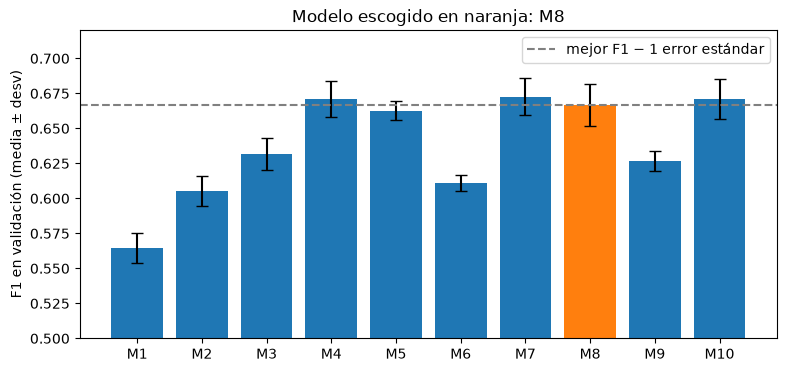

,modelo,max_depth,min_split_samples,criterio,f1_media,f1_desv,hojas,tiempo_s
7,M8,10,300,gini,0.667,0.015,123,2.6
9,M10,10,50,entropia,0.671,0.014,186,2.5
6,M7,10,50,gini,0.673,0.013,193,2.8
3,M4,10,2,gini,0.671,0.013,297,5.9


In [8]:
mejor = escoger_mejor(tabla, k=K)
params_mejor = COMBINACIONES[mejor.name]

top = tabla.loc[tabla["f1_media"].idxmax()]
limite = top["f1_media"] - top["f1_desv"] / np.sqrt(K)
print(f"Mejor F1: {top['modelo']} = {top['f1_media']:.4f}  ->  límite de un error estándar: {limite:.4f}")
print(f"Modelo escogido: {mejor['modelo']} {params_mejor}")

colores = ["tab:orange" if m == mejor["modelo"] else "tab:blue" for m in tabla["modelo"]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(tabla["modelo"], tabla["f1_media"], yerr=tabla["f1_desv"], color=colores, capsize=4)
ax.axhline(limite, color="gray", linestyle="--", label="mejor F1 − 1 error estándar")
ax.set_ylim(0.5, 0.72)
ax.set_ylabel("F1 en validación (media ± desv)")
ax.set_title(f"Modelo escogido en naranja: {mejor['modelo']}")
ax.legend()
plt.show()

candidatos = tabla[tabla["f1_media"] >= limite].sort_values("hojas")
candidatos[["modelo", "max_depth", "min_split_samples", "criterio", "f1_media", "f1_desv", "hojas", "tiempo_s"]]

**Justificación.** El F1 más alto es el de M7 (0.673), pero M4, M10 y **M8** están dentro de un error estándar de él.
De esos cuatro, M8 (`max_depth=10`, `min_split_samples=300`, gini) es el más simple: 123 hojas contra 193 de M7 y 297 de M4.
También es el que menos sobreajusta de los de profundidad 10 (accuracy train 0.866 vs validación 0.857). Perder 0.006 de F1, una diferencia menor que el ruido entre folds, a cambio de un árbol 36 % más pequeño
es un buen intercambio.

M8 entra al grupo por poco (0.6672 contra un límite de 0.6667), así que M7 también sería una elección razonable. La evaluación en test, al final, confirma que M8 rinde lo que prometía la validación.

Se entrena ahora con **todo** el train para verlo por dentro:

In [9]:
modelo_final = ArbolDecision(**params_mejor)
modelo_final.fit(X_train, y_train)
modelo_final.imprimir(max_niveles=3)

relationship en {Not-in-family, Other-relative, Own-child, Unmarried} (muestras=39074, impureza=0.364)
    sí: capital-gain <= 7055.500 (muestras=21414, impureza=0.121)
        sí: education en {10th, 11th, 12th, 1st-4th, …} (muestras=21045, impureza=0.093)
            sí: clase=0 (muestras=16857, impureza=0.048)
            no: clase=0 (muestras=4188, impureza=0.250)
        no: age <= 20.000 (muestras=369, impureza=0.058)
            sí: clase=0 (muestras=5, impureza=0.320)
            no: clase=1 (muestras=364, impureza=0.038)
    no: education en {10th, 11th, 12th, 1st-4th, …} (muestras=17660, impureza=0.495)
        sí: capital-gain <= 5095.500 (muestras=11817, impureza=0.440)
            sí: clase=0 (muestras=11260, impureza=0.415)
            no: clase=1 (muestras=557, impureza=0.035)
        no: capital-gain <= 5095.500 (muestras=5843, impureza=0.419)
            sí: clase=1 (muestras=4985, impureza=0.454)
            no: clase=1 (muestras=858, impureza=0.007)


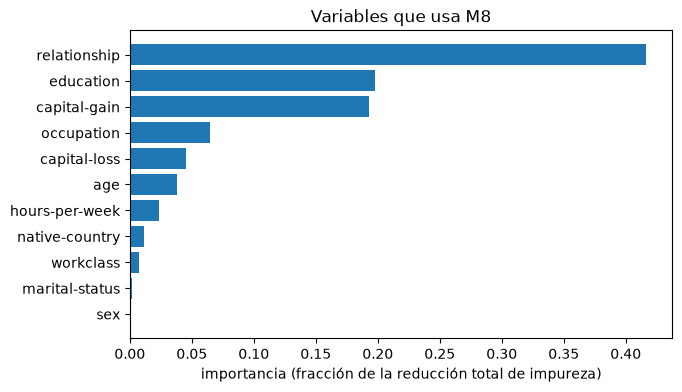

In [10]:
importancia = pd.Series(modelo_final.importancia_variables())
importancia = importancia[importancia > 0].sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importancia.index, importancia.values)
ax.set_xlabel("importancia (fracción de la reducción total de impureza)")
ax.set_title(f"Variables que usa {mejor['modelo']}")
plt.show()

**Qué aprendió el árbol.** La primera pregunta es `relationship`: separa a los esposos/esposas (`Husband`, `Wife`) del resto.
En la práctica es "¿está casado y vive en pareja?", y por sí sola explica ~42 % de la reducción de impureza.
Para los no casados, lo primero que mira son las ganancias de capital altas (`capital-gain`). Para los casados, el
siguiente factor es el nivel de `education`. Esas tres variables suman más del 80 % de la importancia; `occupation`, `age` y
las horas por semana afinan el resto. `race` y `sex` tienen importancia baja o nula: el árbol las usa poco porque
`relationship` ya captura buena parte de esa información. `education-num` tiene importancia 0 porque es la misma información que `education` en forma numérica: una vez que el árbol cortó por una, la otra no aporta nada nuevo.

## Evaluación en test

Hasta aquí el test no se había usado. Se evalúa una sola vez el modelo final y se compara con lo que predijo la validación cruzada.

In [11]:
y_pred = modelo_final.predict(X_test)
metricas = {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

comparacion = pd.DataFrame({
    "validación (media)": [mejor[f"{m}_media"] for m in metricas],
    "validación (desv)": [mejor[f"{m}_desv"] for m in metricas],
    "test": [f(y_test, y_pred) for f in metricas.values()],
}, index=list(metricas))
comparacion

,validación (media),validación (desv),test
accuracy,0.857,0.003,0.856
precision,0.749,0.008,0.750
recall,0.601,0.027,0.600
f1,0.667,0.015,0.667


In [12]:
matriz = pd.DataFrame(
    [[np.sum((y_test == 0) & (y_pred == 0)), np.sum((y_test == 0) & (y_pred == 1))],
     [np.sum((y_test == 1) & (y_pred == 0)), np.sum((y_test == 1) & (y_pred == 1))]],
    index=["real <=50K", "real >50K"], columns=["predice <=50K", "predice >50K"])
print(f"Línea base (predecir siempre <=50K): accuracy = {np.mean(y_test == 0):.3f}, F1 = 0")
matriz

Línea base (predecir siempre <=50K): accuracy = 0.760, F1 = 0


,predice <=50K,predice >50K
real <=50K,6957,468
real >50K,937,1406


**Conclusiones.**

- En test el modelo obtiene accuracy 0.856 y F1 0.667, prácticamente lo mismo que estimó la validación cruzada
  (0.857 y 0.667 ± 0.015). La validación cruzada fue un buen estimador del rendimiento en datos nuevos y el modelo
  **no está sobreajustado**.
- Supera claramente a la línea base de la clase mayoritaria (0.760 de accuracy y F1 = 0).
- La matriz de confusión muestra su debilidad: de las ~2340 personas que sí ganan más de 50K, detecta ~60 % (recall).
  Cuando predice ">50K" acierta 3 de cada 4 veces (precision 0.75). Si en la aplicación importara más no dejar escapar positivos,
  se podría bajar el umbral usando `predict_proba` en vez de la clase mayoritaria de la hoja.
- Lo que más influyó en el rendimiento fue la **profundidad**: poca profundidad subajusta y sin límite sobreajusta;
  10 niveles es el punto medio. `min_split_samples` sirvió para simplificar el árbol sin perder rendimiento y el criterio
  (gini o entropía) casi no influyó.